# 04 — Speed lag and segment features

## Problem
Forecasting models need usable past measurements and must identify which road-sensor segment each value belongs to.

## Solution
Create observed-speed lags, time-of-day and weekday features, and sensor ID segment columns from METR-LA. Zero readings are masked and forward-filled for inputs; speed-only data cannot provide flow or occupancy features.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
PREDICTIONS = ROOT / 'results' / 'predictions'
for folder in [FIG, METRICS, PREDICTIONS]:
    folder.mkdir(parents=True, exist_ok=True)
traffic = pd.read_csv(DATA / 'METR-LA.csv', index_col=0, parse_dates=True).astype('float32')
observed = traffic.where(traffic > 0)
speed = observed.ffill().fillna(observed.iloc[:int(len(observed) * .7)].median())
print('Rows:', len(speed), '| sensors/segments:', len(speed.columns), '| speed columns:', len(speed.columns))

Rows: 34272 | sensors/segments: 207 | speed columns: 207


In [2]:
example = speed.iloc[:, :4].copy()
feature_rows = pd.DataFrame(index=speed.index)
for sensor in example.columns:
    for lag in [0, 1, 2, 5, 12]:
        feature_rows[f'{sensor}_speed_lag_{lag + 1}'] = example[sensor].shift(lag)
feature_rows['time_sin'] = np.sin(2 * np.pi * speed.index.hour / 24)
feature_rows['time_cos'] = np.cos(2 * np.pi * speed.index.hour / 24)
feature_rows['weekday'] = speed.index.dayofweek
feature_rows['target_15min'] = example.iloc[:, 0].shift(-3)
feature_rows.dropna().head(200).to_csv(PREDICTIONS / 'metr_la_feature_sample.csv')

lag_correlations = pd.DataFrame({
    f'{lag * 5} min history': [speed.shift(lag).corrwith(speed).mean()]
    for lag in [1, 3, 6, 12]
}).T.rename(columns={0: 'mean_sensor_correlation'})
display(lag_correlations)
print('Saved a small real-data lag-feature sample with sensor IDs as segment labels.')

,mean_sensor_correlation
5 min history,0.862157
15 min history,0.787273
30 min history,0.704675
60 min history,0.570945


Saved a small real-data lag-feature sample with sensor IDs as segment labels.


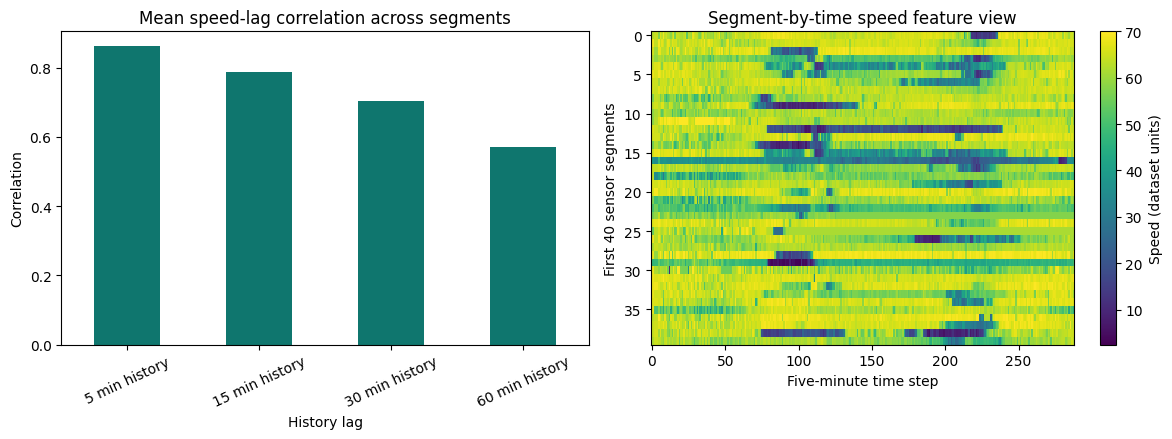

Saved results/figures/17_speed_lag_and_segment_features.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lag_correlations['mean_sensor_correlation'].plot(kind='bar', ax=axes[0], color='#0f766e')
axes[0].set(title='Mean speed-lag correlation across segments', xlabel='History lag', ylabel='Correlation')
axes[0].tick_params(axis='x', rotation=25)
heat = axes[1].imshow(speed.iloc[:288, :40].to_numpy().T, aspect='auto', cmap='viridis', interpolation='nearest')
axes[1].set(title='Segment-by-time speed feature view', xlabel='Five-minute time step', ylabel='First 40 sensor segments')
fig.colorbar(heat, ax=axes[1], label='Speed (dataset units)')
fig.tight_layout()
fig.savefig(FIG / '17_speed_lag_and_segment_features.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/17_speed_lag_and_segment_features.png')